# Import dependencies

In [11]:
# %pip install cupy-cuda13x
# %pip install "cupy-cuda12x[ctk]"
import cupy as np
import copy
import matplotlib.pyplot as plt
import sklearn
import sklearn.datasets
import sklearn.linear_model

 # Define dataset

In [30]:
def load_planar_dataset(seed=1):
    np.random.seed(seed)
    m = 20000 # number of examples
    N = int(m/2) # number of points per class
    D = 2 # dimensionality
    X = np.zeros((m,D)) # data matrix where each row is a single example
    Y = np.zeros((m,1), dtype='uint8') # labels vector (0 for red, 1 for blue)
    a = 4 # maximum ray of the flower

    for j in range(2):
        ix = range(N*j,N*(j+1))
        t = np.linspace(j*3.12,(j+1)*3.12,N) + np.random.randn(N)*0.2 # theta
        r = a*np.sin(8*t) + np.random.randn(N)*0.2 # radius
        X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
        Y[ix] = j
        
    X = X.T
    Y = Y.T

    return X, Y

# Load dataset

In [32]:
X, Y = load_planar_dataset()
X_test, Y_test = load_planar_dataset(seed=99)

# Visualize the data

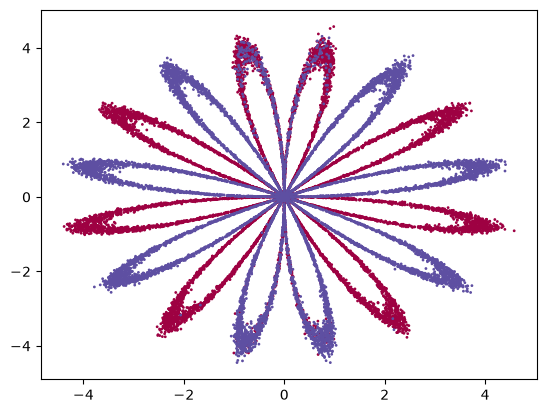

In [14]:
plt.scatter(X[0, :].get(), X[1, :].get(), c=Y.get(), s=1, cmap=plt.cm.Spectral);

In [15]:
print ('The shape of X is: ', X.shape)
print ('The shape of Y is: ', Y.shape)
print ('I have m = %d training examples!'% (X.shape[1]))

The shape of X is:  (2, 20000)
The shape of Y is:  (1, 20000)
I have m = 20000 training examples!


# Define the hidden layer size

In [16]:
hidden_layer_nodes = 4

def layer_sizes(X, Y):
    n_x = X.shape[0]
    n_h = hidden_layer_nodes
    n_y = Y.shape[0]

    return (n_x, n_h, n_y)

# Define activation function

In [17]:
def sigmoid(x):
    
    s = 1/(1+np.exp(-x))
    return s

# Define function for parameter (weight and bias) initialization

In [18]:
def initialize_parameters(n_x, n_h, n_y):
    
    np.random.seed(2)

    W1 = np.random.randn(n_h,n_x) * 0.01
    b1 = np.zeros((n_h,1))
    
    W2 = np.random.randn(n_y,n_h) * 0.01
    b2 = np.zeros((n_y,1))

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

# Forward propagation

In [19]:

def forward_propagation(X, parameters):
    
    W1 = parameters["W1"]
    b1 = parameters["b1"]
    W2 = parameters["W2"]
    b2 = parameters["b2"]
    
    Z1 = np.dot(W1,X) + b1
    A1 = np.tanh(Z1)
    
    Z2 = np.dot(W2,A1) + b2
    A2 = sigmoid(Z2)
    
    cache = {"Z1": Z1,
             "A1": A1,
             "Z2": Z2,
             "A2": A2}
    
    return A2, cache

# Compute cost

In [20]:
def compute_cost(A2, Y):

    m = Y.shape[1] # number of examples

    logprobs = np.multiply(Y, np.log(A2)) + np.multiply((1 - Y), np.log(1 - A2))
    cost = - np.multiply(1/m, np.sum(logprobs))  
    cost = float(np.squeeze(cost))                             
    
    return cost

# Backward propagation

In [21]:
def backward_propagation(parameters, cache, X, Y):

    m = X.shape[1]
    W1 = parameters["W1"]
    W2 = parameters["W2"]
    
    A1 = cache["A1"]
    A2 = cache["A2"]

    dZ2 = A2 - Y
    dW2 = np.multiply(1/m, np.dot(dZ2, np.transpose(A1)))
    db2 = np.multiply(1/m, np.sum(dZ2, axis = 1, keepdims = True))
    dZ1 = np.multiply(np.dot(np.transpose(W2), dZ2), (1 - np.power(A1, 2)))
    dW1 = np.multiply(1/m, np.dot(dZ1, np.transpose(X)))
    db1 = np.multiply(1/m, np.sum(dZ1, axis = 1, keepdims = True))
    
    grads = {"dW1": dW1,
             "db1": db1,
             "dW2": dW2,
             "db2": db2}
    
    return grads

# Update parameters

In [22]:

def update_parameters(parameters, grads, learning_rate = 1.2):
    
    W1 = copy.deepcopy(parameters["W1"]) 
    b1 = copy.deepcopy(parameters["b1"]) 
    W2 = copy.deepcopy(parameters["W2"]) 
    b2 = copy.deepcopy(parameters["b2"]) 
    
    dW1 = copy.deepcopy(grads["dW1"]) 
    db1 = copy.deepcopy(grads["db1"])
    dW2 = copy.deepcopy(grads["dW2"])
    db2 = copy.deepcopy(grads["db2"])
    
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters

# Full NN model

In [23]:

def nn_model(X, Y, n_h, num_iterations = 10000, print_cost=False, learning_rate=1.2):
    
    np.random.seed(3)
    n_x = layer_sizes(X, Y)[0]
    n_y = layer_sizes(X, Y)[2]
    
    parameters = initialize_parameters(n_x, n_h, n_y)
   
    for i in range(0, num_iterations):
        
        A2, cache = forward_propagation(X, parameters)
        cost = compute_cost(A2, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads, learning_rate = learning_rate)
        
        # Print the cost every 1000 iterations
        if print_cost and i % 1000 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))

    return parameters

# Test on our dataset

In [24]:
parameters = nn_model(X, Y, n_h = 4, num_iterations = 100000, print_cost=True)

Cost after iteration 0: 0.693146
Cost after iteration 1000: 0.550806
Cost after iteration 2000: 0.533002
Cost after iteration 3000: 0.528570
Cost after iteration 4000: 0.525795
Cost after iteration 5000: 0.523735
Cost after iteration 6000: 0.522113
Cost after iteration 7000: 0.520782
Cost after iteration 8000: 0.519657
Cost after iteration 9000: 0.518685
Cost after iteration 10000: 0.517830
Cost after iteration 11000: 0.517068
Cost after iteration 12000: 0.516382
Cost after iteration 13000: 0.515759
Cost after iteration 14000: 0.515188
Cost after iteration 15000: 0.514662
Cost after iteration 16000: 0.514174
Cost after iteration 17000: 0.513720
Cost after iteration 18000: 0.513295
Cost after iteration 19000: 0.512896
Cost after iteration 20000: 0.512520
Cost after iteration 21000: 0.512164
Cost after iteration 22000: 0.511827
Cost after iteration 23000: 0.511507
Cost after iteration 24000: 0.511203
Cost after iteration 25000: 0.510912
Cost after iteration 26000: 0.510634
Cost after ite

# Predict function

In [25]:
def predict(parameters, X):

    A2, cache = forward_propagation(X, parameters)
    predictions = (A2 > 0.5)

    return predictions

# Plot decision boundary

In [26]:
def plot_decision_boundary(model, X, y):
    # Set min and max values and give it some padding
    x_min, x_max = float(X[0, :].min()) - 1, float(X[0, :].max()) + 1
    y_min, y_max = float(X[1, :].min()) - 1, float(X[1, :].max()) + 1
    h = 0.02
    # Generate a grid of points with distance h between them
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    # Predict the function value for the whole grid
    Z = model(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    # Plot the contour and training examples
    plt.contourf(xx.get(), yy.get(), Z.get(), cmap=plt.cm.Spectral)
    plt.ylabel('x2')
    plt.xlabel('x1')
    plt.scatter(X[0, :].get(), X[1, :].get(), c=y.get(), s=1, cmap=plt.cm.Spectral)

Text(0.5, 1.0, 'Decision Boundary for hidden layer size 4')

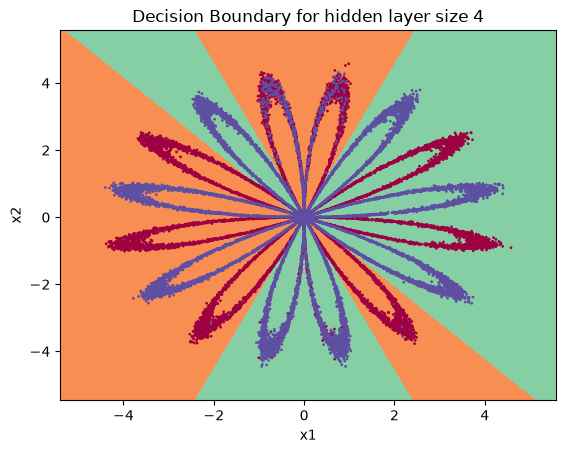

In [27]:
plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
plt.title("Decision Boundary for hidden layer size " + str(4))

# Tuning hidden layer size

Accuracy for 1 hidden units: 47.125 %
Accuracy for 2 hidden units: 55.315000000000005 %
Accuracy for 3 hidden units: 66.29 %
Accuracy for 4 hidden units: 66.595 %
Accuracy for 5 hidden units: 78.53999999999999 %
Accuracy for 10 hidden units: 92.39500000000001 %
Accuracy for 20 hidden units: 92.47999999999999 %
Accuracy for 50 hidden units: 92.45 %
Accuracy for 200 hidden units: 91.97 %
Accuracy for 500 hidden units: 91.705 %


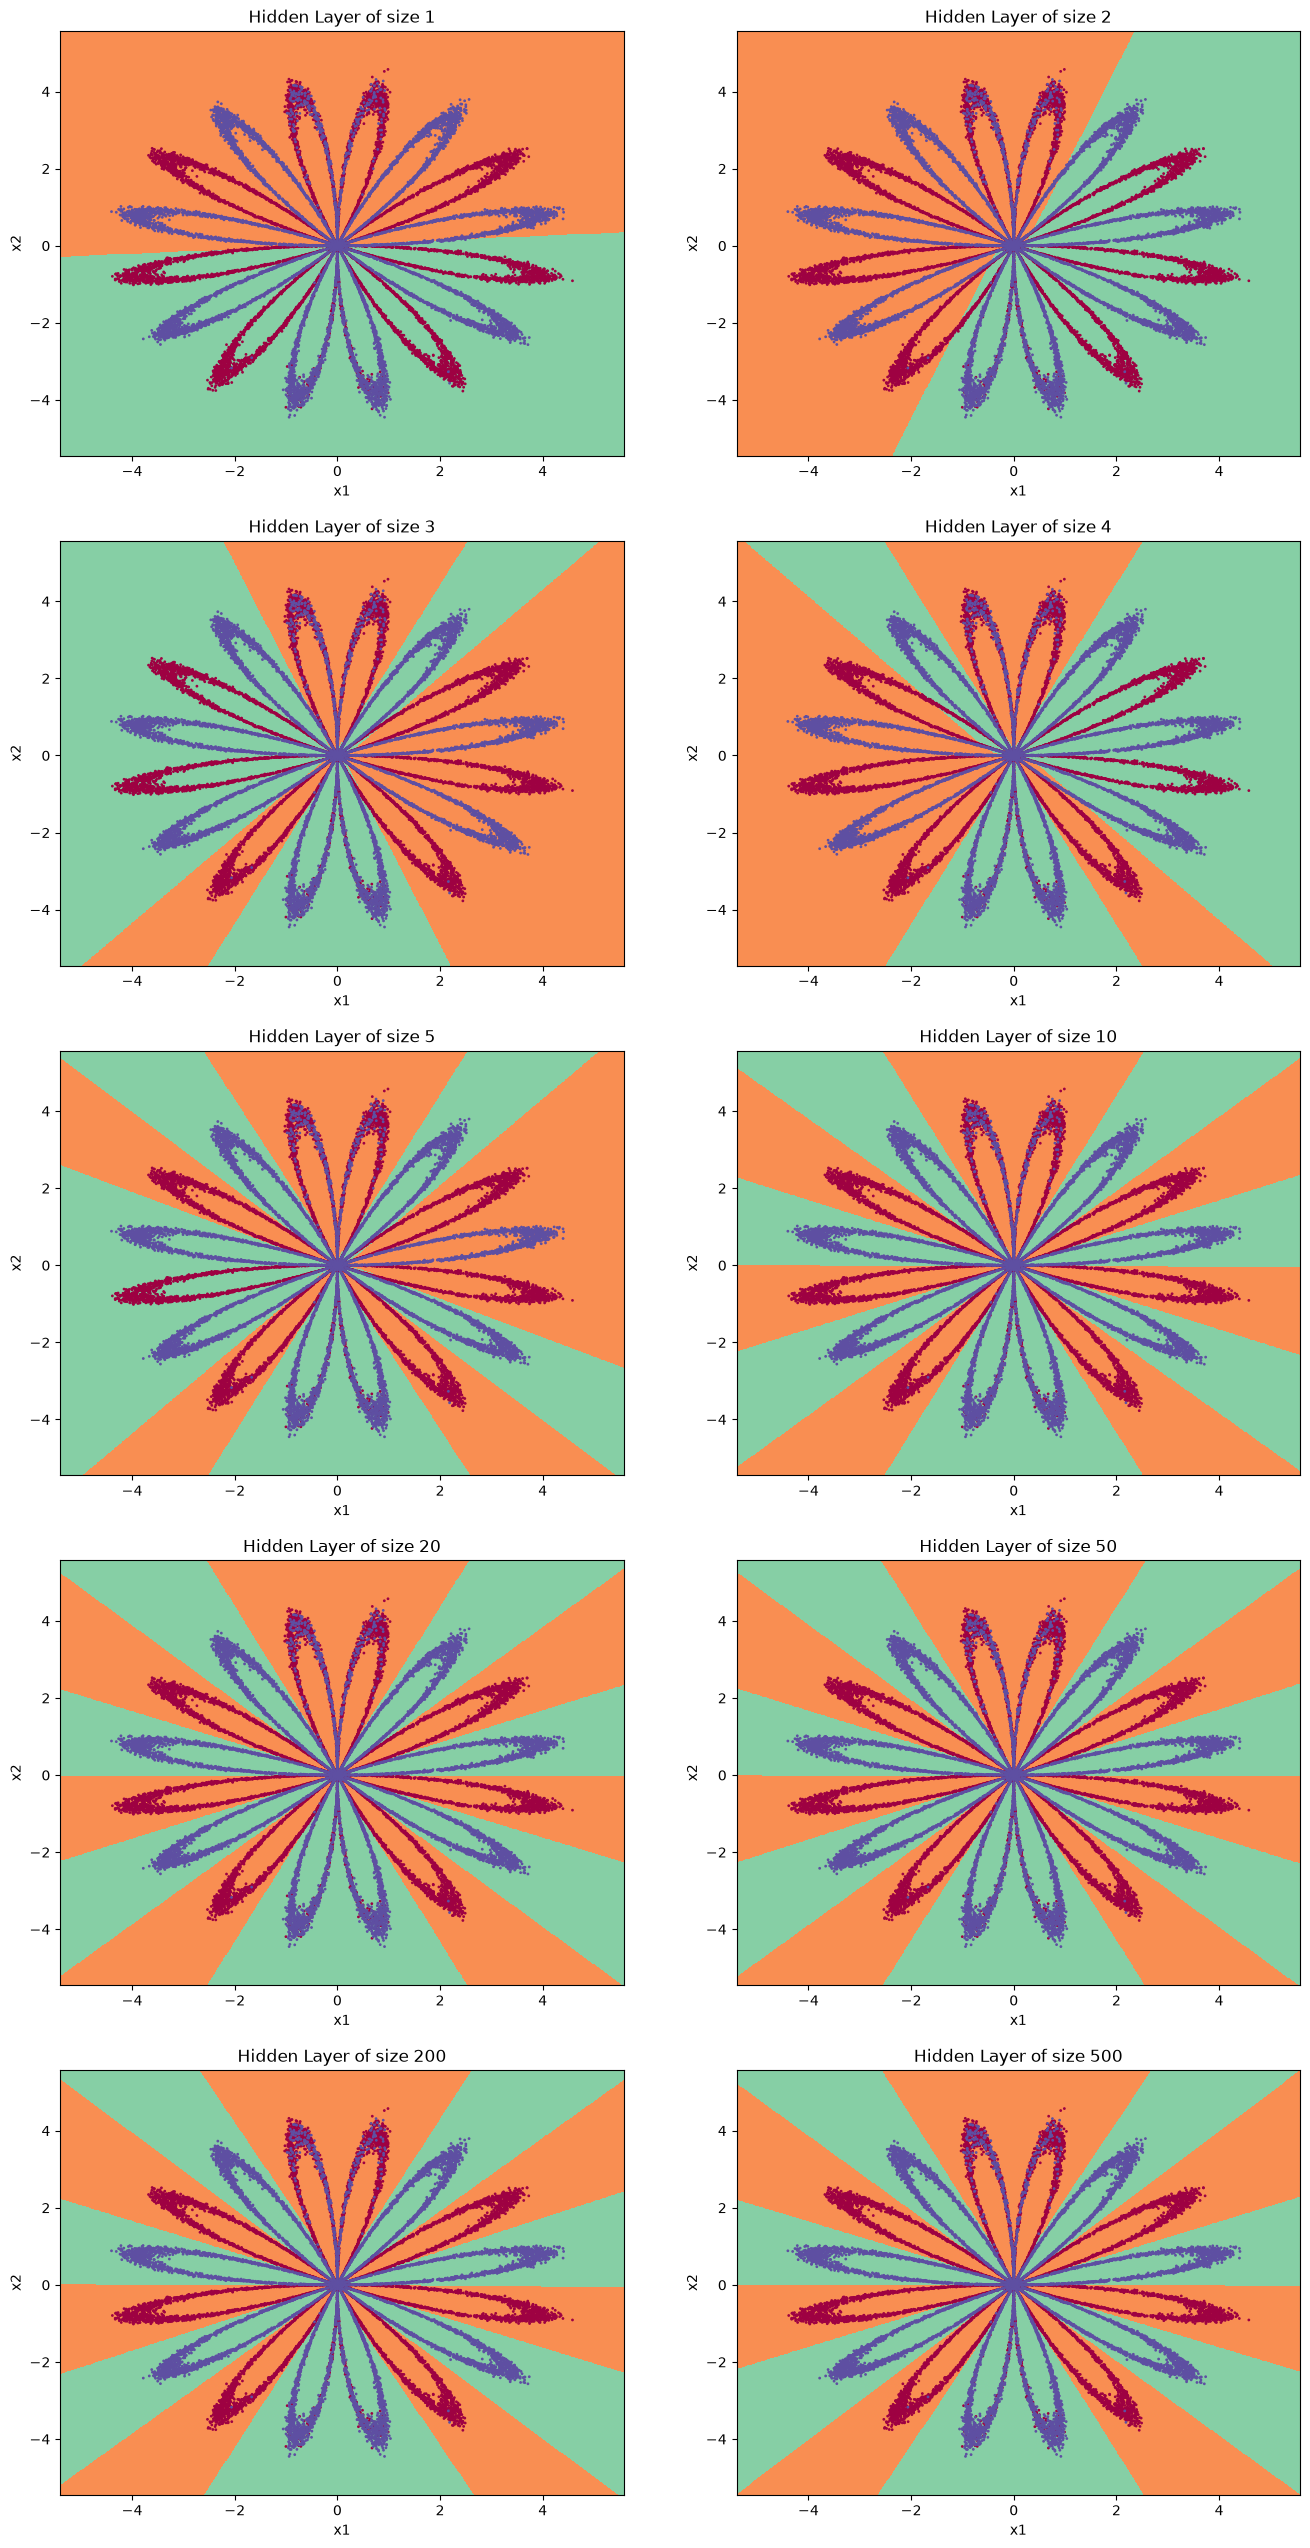

In [29]:
plt.figure(figsize=(16, 32))
hidden_layer_sizes = [1, 2, 3, 4, 5, 10, 20, 50, 200, 500]
for i, n_h in enumerate(hidden_layer_sizes):
    plt.subplot(5, 2, i+1)
    plt.title('Hidden Layer of size %d' % n_h)
    parameters = nn_model(X, Y, n_h, num_iterations = 20000, learning_rate=0.5)
    plot_decision_boundary(lambda x: predict(parameters, x.T), X, Y)
    predictions = predict(parameters, X)
    accuracy = float(np.mean(predictions == Y) * 100)
    print ("Accuracy for {} hidden units: {} %".format(n_h, accuracy))

# Conclusions here

Sweet spot for hidden units in this task seemed to be around 3-10. Under 3 it was underfitting and above 10 it was stuck at 90% and didn't really change anything. Also there was not test data, so we can't calculate for sure.

Also note this was for the original data, I upped all the sizes and amounts since I transfered this to my personal PC and I have power to spare. (it did however take long to make this run on my GPU, instead of CPU). This was 20000points, 8 petals and ran on GPU with CuPy.
As for my new data, there is a significant jump from 1 to 3. From 3 to 4 there is almost no real change but at 5 and then 10 there is signicant increase, altough above 10 the results seem to dimminish and are not worth the time. 

Additionally I didnt get any curveson more units, to my understanding (with claude explaining) those usually mean slight overfitting for noise and can only be seen on extreme overfitting or just not large dataset.

In [34]:
hidden_layer_sizes = [1, 2, 3, 4, 5, 10, 20, 50, 200, 500]
for i, n_h in enumerate(hidden_layer_sizes):
    parameters = nn_model(X, Y, n_h, num_iterations = 20000, learning_rate=0.5)
    train_acc = float(np.mean(predict(parameters, X) == Y) * 100)
    test_acc = float(np.mean(predict(parameters, X_test) == Y_test) * 100)
    print(f"{n_h} hidden units: train {train_acc:.2f}% | test {test_acc:.2f}% | gap {train_acc - test_acc:.2f}")

1 hidden units: train 47.12% | test 46.88% | gap 0.24
2 hidden units: train 55.32% | test 54.97% | gap 0.34
3 hidden units: train 66.29% | test 67.28% | gap -0.99
4 hidden units: train 66.59% | test 66.67% | gap -0.08
5 hidden units: train 78.54% | test 78.80% | gap -0.26
10 hidden units: train 92.40% | test 92.40% | gap 0.00
20 hidden units: train 92.48% | test 92.55% | gap -0.08
50 hidden units: train 92.45% | test 92.50% | gap -0.05
200 hidden units: train 91.97% | test 92.03% | gap -0.06
500 hidden units: train 91.70% | test 91.90% | gap -0.19
